# Part 5 – Price cut without Panem: simulation from the randomized price response

**Question.** What would revenue have been in the five cut regions in 2019 without the cut? Notebook 1 answered this with Panem as the comparison. Here the answer comes from the join and cancel models instead. Their price effects are estimated from discount depths randomized within each season in the cut regions, so nothing below uses Panem.

**Method.** Start from the actual state at winter 2019, the last season before the cut, and simulate spring to fall 2019 twice: with the actual \$12 base price, and with every price \$3 higher (no cut). The join and cancel models are the ones saved by notebooks 3 and 4; nothing is refit here. Both runs use the fitted 2019 season levels and the same random draws, so the only difference is the price. The actual run also checks the simulator: it should reproduce what really happened in 2019.

**Findings**

* **The simulator reproduces 2019.** Under the actual prices, simulated members are within 0.6% of the actual count in each season, and revenue within 1.2%.
* **The cut raised membership a lot and revenue a little.** Over the three post-cut seasons, the cut regions have +41% to +47% more members than without the cut, and +8% to +12% more revenue per customer.
* **That agrees with the regional comparison** (+1.5% revenue per customer, with a range of about −25% to +38%, or +7.8% without spring 2018), and is much more precise. The revenue effect is −9% to −7% in spring, +11% to +16% in summer, +25% to +30% in fall by season, so it grows as the extra members accumulate.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter
from scipy.special import expit

import utils as u

u.apply_style()
CUT = u.CUT_T                                              # spring 2019
SCORES = ['tv', 'radio', 'social', 'podcast']
OFFER_SHARE, DEPTHS, REPS = 0.25, np.arange(1, 6), 5        # today's policy; simulation repeats per scenario
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#52514e'


def predict(params, data):
    # P = expit(X b), with X built from the coefficient names saved by statsmodels:
    # 'Intercept', numeric columns, and 'C(col)[T.level]' dummies
    xb = np.full(len(data), params['Intercept'])
    for name, b in params.drop('Intercept').items():
        if name.startswith('C('):
            col, level = name[2:-1].split(')[T.')
            values = data[col]
            xb += b * (values == (float(level) if pd.api.types.is_numeric_dtype(values) else level)).to_numpy()
        else:
            xb += b * data[name].to_numpy(dtype=float)
    return expit(xb)


join_params = pd.read_csv('outputs/join_model_params.csv', index_col=0)['coefficient']        # notebook 3
cancel_params = pd.read_csv('outputs/cancel_model_params.csv', index_col=0)['coefficient']    # notebook 4


panel = u.load_panel('data/customer_panel.csv', extra_cols=('customer_id', 'discount_flag', 'search_flag'))

In [7]:
join_params

Intercept                             -1.526604
C(region_name)[T.essos]               -0.127803
C(region_name)[T.hogsmeade]           -0.211677
C(region_name)[T.hundred acre wood]   -0.273470
C(region_name)[T.westeros]            -0.109873
C(t)[T.4]                              0.273757
C(t)[T.5]                             -1.454106
C(t)[T.6]                              1.472094
C(t)[T.7]                             -0.486714
C(t)[T.8]                              0.986481
C(t)[T.9]                             -0.987690
C(t)[T.10]                            -0.260551
C(t)[T.11]                             0.691374
price                                 -0.411711
offer                                  0.043940
search_lag                             0.060247
tv                                     0.115034
radio                                  0.075007
social                                 1.453747
podcast                                4.072928
ever_member                            0

## 1. Data and the saved models

The coefficients come from notebooks 3 (joining) and 4 (cancelling). The frame below builds each customer's state and covariates in the five cut regions, defined the same way as in those notebooks. The last check confirms the saved coefficients reproduce each 2019 season's actual joining and cancel rates.

In [2]:
df = panel[panel['region_name'].ne(u.CONTROL)].sort_values(['customer_id', 't']).reset_index(drop=True)
del panel
df['revenue'] = df['sign_up_flag'] * df['membership_price']
df['prev_member'] = df.groupby('customer_id')['sign_up_flag'].shift(1)
df['price_lag'] = df.groupby('customer_id')['membership_price'].shift(1)
df['search_lag'] = df.groupby('customer_id')['search_flag'].shift(1)
df['ever_member'] = df.groupby('customer_id')['sign_up_flag'].cummax().groupby(df['customer_id']).shift(1).fillna(0).astype(int)
spell = (df['sign_up_flag'].eq(1) & df['prev_member'].fillna(0).eq(0)).groupby(df['customer_id']).cumsum()
df['tenure'] = np.where(df['sign_up_flag'].eq(1), df.groupby(['customer_id', spell]).cumcount() + 1, 0)
df['tenure_group'] = df.groupby('customer_id')['tenure'].shift(1).clip(upper=8)
df['score_year'] = np.where(df['t'].ge(3), 2017 + (df['t'] - 3) // 4, -1)        # summer refresh applies from fall

scores = (pd.read_csv('data/customer_propensities.csv',
                      usecols=['customer_id', 'year', *[f'customer_{s}_score' for s in SCORES]])
            .rename(columns={'year': 'score_year', **{f'customer_{s}_score': s for s in SCORES}}))
df = (df.merge(scores, on=['customer_id', 'score_year'], how='left', validate='many_to_one')
        .rename(columns={'membership_price': 'price', 'discount_flag': 'offer'}))
df['price_post'] = df['price'] * df['t'].ge(CUT)

print(f"Join model, price: {join_params['price']:.3f}")
print(f"Cancel model, price: {cancel_params['price']:.3f} before the cut, "
      f"{cancel_params['price'] + cancel_params['price_post']:.3f} after")

# Check: the saved coefficients reproduce each 2019 season's actual rates (in-sample)
s19 = df[df['t'].between(CUT, 11)]
prospects, members = s19[s19['prev_member'].eq(0)], s19[s19['prev_member'].eq(1)]
rates = pd.DataFrame({
    'joining, actual': prospects.groupby('t')['sign_up_flag'].mean(),
    'joining, predicted': pd.Series(predict(join_params, prospects), index=prospects.index).groupby(prospects['t']).mean(),
    'cancelling, actual': 1 - members.groupby('t')['sign_up_flag'].mean(),
    'cancelling, predicted': pd.Series(predict(cancel_params, members), index=members.index).groupby(members['t']).mean(),
}).rename(index=u.period_label)
rates.round(4)

Join model, price: -0.412
Cancel model, price: 0.298 before the cut, 0.241 after


,"joining, actual","joining, predicted","cancelling, actual","cancelling, predicted"
t,,,,
Spr 2019,0.0442,0.0442,0.0832,0.0832
Sum 2019,0.0805,0.0805,0.0916,0.0916
Fall 2019,0.1359,0.1359,0.0718,0.0718


## 2. The simulator

Each season, every customer faces today's offer policy: 25% of non-members are offered a random \$1–\$5 off, and every member gets a random \$1–\$5 off. The two models give each customer's chance of joining or cancelling at that price, and a random draw decides what happens. Members carry their tenure and last price forward, people who cancel can rejoin later, and revenue is what members pay.

For the no-cut run, every price is \$3 higher. The join model's single price slope then shifts joining automatically. For cancelling, the model has one slope before the cut (0.30) and one after (0.24), and it can't tell whether the flatter slope reflects the period or the lower prices. So the no-cut run is done with each slope, giving a range.

In [3]:
start = df[df['t'].eq(CUT - 1)].set_index('customer_id')                      # winter 2019
seasons = {k: df[df['t'].eq(k)].set_index('customer_id') for k in range(CUT, 12)}
assert all((s.index == start.index).all() for s in seasons.values())


def simulate(base, member_slope='post', seed=0):
    # Spring-fall 2019 from the winter 2019 state. base: $12 actual, $15 no cut.
    rng = np.random.default_rng(seed)
    member = start['sign_up_flag'].eq(1).to_numpy()
    ever = start['ever_member'].eq(1).to_numpy() | member                       # a member at some point so far
    tenure = start['tenure'].to_numpy()
    last_price = start['price'].to_numpy(dtype=float)
    rows = []
    for k, s in seasons.items():
        n = len(s)
        offered = rng.random(n) < OFFER_SHARE
        depth = rng.choice(DEPTHS, n)
        u_join, u_cancel = rng.random(n), rng.random(n)
        price = np.where(member | offered, base - depth, base).astype(float)
        # 'pre': the extra $3 is valued at the pre-cut member slope; 'post': at the post-cut slope
        price_post = price - (base - 12) if member_slope == 'pre' else price
        X = s.assign(price=price, offer=(offered & ~member).astype(int), ever_member=ever.astype(int),
                     price_lag=last_price, tenure_group=np.clip(tenure, 1, 8), price_post=price_post)
        stays = member & (u_cancel >= predict(cancel_params, X))
        joins = ~member & (u_join < predict(join_params, X))
        member = stays | joins
        rows.append({'t': k, 'members': member.sum(), 'revenue': price[member].sum()})
        ever |= member
        tenure = np.where(stays, tenure + 1, np.where(joins, 1, 0))
        last_price = price
    return pd.DataFrame(rows).set_index('t')


scenarios = {
    'actual prices (base $12)': dict(base=12),
    'no cut, post-cut member slope': dict(base=15, member_slope='post'),
    'no cut, pre-cut member slope': dict(base=15, member_slope='pre'),
}
runs = {name: pd.concat([simulate(**kw, seed=s) for s in range(REPS)]).groupby('t').mean()
        for name, kw in scenarios.items()}

## 3. Check: does the simulator reproduce 2019?

Simulated members and revenue under the actual prices, against what actually happened. The season levels come from the fitted models, so a large miss would point to a problem in the simulator itself, not in the models.

In [4]:
actual = df[df['t'].between(CUT, 11)].groupby('t').agg(members=('sign_up_flag', 'sum'), revenue=('revenue', 'sum'))
sim = runs['actual prices (base $12)']
check = pd.DataFrame({'actual members': actual['members'], 'simulated members': sim['members'],
                      'members gap %': 100 * (sim['members'] / actual['members'] - 1),
                      'actual revenue': actual['revenue'], 'simulated revenue': sim['revenue'],
                      'revenue gap %': 100 * (sim['revenue'] / actual['revenue'] - 1)})
check.index = [u.period_label(k) for k in check.index]
check.round(1)

,actual members,simulated members,members gap %,actual revenue,simulated revenue,revenue gap %
Spr 2019,87153,87196.4,0.0,785826,795030.6,1.2
Sum 2019,100959,100371.4,-0.6,930636,926611.8,-0.4
Fall 2019,128602,129146.4,0.4,1214989,1213307.0,-0.1


## 4. The cut's effect

Effect = log(actual-price run ÷ no-cut run), by season and averaged over the three post-cut seasons, in the same units as the difference-in-differences in notebook 1.

In [5]:
n_customers = len(start)
base_run = runs['actual prices (base $12)']
effects = {}
for name in ['no cut, post-cut member slope', 'no cut, pre-cut member slope']:
    no_cut = runs[name]
    effects[name] = pd.DataFrame({
        'revenue per customer, actual prices': base_run['revenue'] / n_customers,
        'revenue per customer, no cut': no_cut['revenue'] / n_customers,
        'members effect %': 100 * np.expm1(np.log(base_run['members'] / no_cut['members'])),
        'revenue effect %': 100 * np.expm1(np.log(base_run['revenue'] / no_cut['revenue'])),
    })
effect_table = pd.concat(effects, names=['scenario', 't']).rename(index=u.period_label, level='t')
display(effect_table.round(2))

summary = pd.DataFrame({name: {
    'members effect %, 3-season average': 100 * np.expm1(np.log(base_run['members'] / runs[name]['members']).mean()),
    'revenue per customer effect %, 3-season average': 100 * np.expm1(np.log(base_run['revenue'] / runs[name]['revenue']).mean()),
} for name in effects}).T
summary.loc['difference-in-differences vs Panem (notebook 1)'] = [np.nan, 1.5]
summary.round(1)

revenue per customer, actual prices  \
scenario                      t                                                
no cut, post-cut member slope Spr 2019                                  2.22   
                              Sum 2019                                  2.59   
                              Fall 2019                                 3.39   
no cut, pre-cut member slope  Spr 2019                                  2.22   
                              Sum 2019                                  2.59   
                              Fall 2019                                 3.39   

                                         revenue per customer, no cut  \
scenario                      t                                         
no cut, post-cut member slope Spr 2019                           2.45   
                              Sum 2019                           2.34   
                              Fall 2019                          2.72   
no cut, pre-cut member slope  Spr 2019                           2.38   
                              Sum 2019                           2.23   
                              Fall 2019                          2.60   

                                         members effect %  revenue effect %  
scenario                      t                                              
no cut, post-cut member slope Spr 2019              19.23             -9.24  
                              Sum 2019              44.59             10.69  
                              Fall 2019             62.72             24.75  
no cut, pre-cut member slope  Spr 2019              22.41             -6.75  
                              Sum 2019              51.57             16.04  
                              Fall 2019             70.41             30.43

,"members effect %, 3-season average","revenue per customer effect %, 3-season average"
"no cut, post-cut member slope",41.0,7.8
"no cut, pre-cut member slope",46.8,12.2
difference-in-differences vs Panem (notebook 1),NaN,1.5


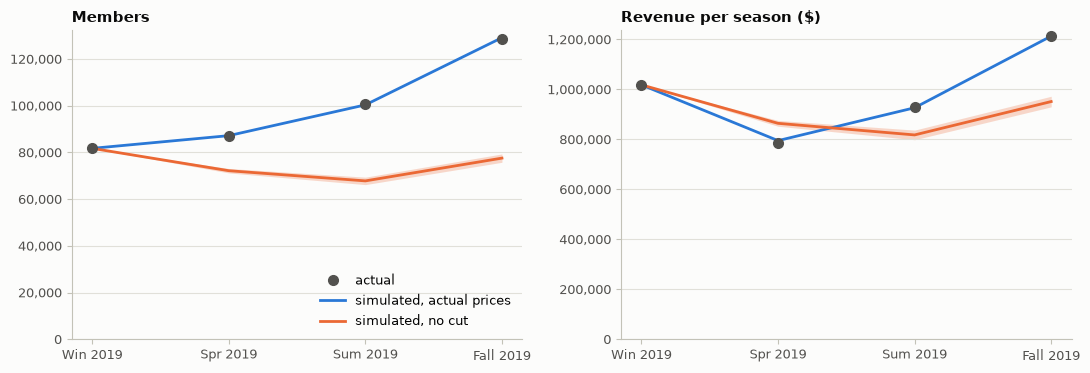

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ts = [CUT - 1, *range(CUT, 12)]
labels = [u.period_label(k) for k in ts]
start_point = {'members': start['sign_up_flag'].sum(), 'revenue': start['revenue'].sum()}
for ax, col, title in [(axes[0], 'members', 'Members'), (axes[1], 'revenue', 'Revenue per season ($)')]:
    actual_line = [start_point[col], *actual[col]]
    ax.plot(ts, actual_line, 'o', color=GRAY, ms=7, label='actual', zorder=4)
    ax.plot(ts, [start_point[col], *runs['actual prices (base $12)'][col]], color=BLUE, lw=2, label='simulated, actual prices')
    lo = [start_point[col], *np.minimum(runs['no cut, post-cut member slope'][col], runs['no cut, pre-cut member slope'][col])]
    hi = [start_point[col], *np.maximum(runs['no cut, post-cut member slope'][col], runs['no cut, pre-cut member slope'][col])]
    ax.fill_between(ts, lo, hi, color=ORANGE, alpha=0.25, lw=0)
    ax.plot(ts, [(a + b) / 2 for a, b in zip(lo, hi)], color=ORANGE, lw=2, label='simulated, no cut')
    ax.set_xticks(ts, labels)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.set_title(title, loc='left')
axes[0].legend(frameon=False, loc='lower right')
fig.tight_layout()
plt.show()

**Reading**

* **The simulator works.** With the fitted season levels, it lands within 0.6% of actual members and 1.2% of actual revenue in every post-cut season.
* **Without the cut, membership would have been much lower.** Averaged over the three seasons, the cut regions have +41% to +47% more members because of the cut, close to the roughly +35% the regional comparison suggested.
* **Revenue rose a little.** Revenue per customer is +8% to +12% higher, and the effect grows season by season (−9% to −7% in spring, +11% to +16% in summer, +25% to +30% in fall), as the extra members build up while the lower price applies from the start.
* **It agrees with the regional comparison and is much tighter.** The difference-in-differences gave +1.5%, with a range of about −25% to +38% (+7.8% without spring 2018). The simulation lands inside that range, and its own uncertainty comes mainly from which member slope applies (the two no-cut runs).

**Assumptions**

* A \$3 change in the base price works like \$3 more off. The join model's offer term is small (+0.04), which supports this.
* Everything else about 2019 stays as it was: the season levels are taken as given, with no spillovers such as word of mouth from the extra members.
* Members at the full \$15 are one dollar beyond any member price observed in the data.
* Results average 5 simulation runs with the same random draws in each scenario, so the comparison isn't driven by chance.